In [2]:
# ==============================================================================
# BƯỚC 0: KIỂM TRA GOOGLE COLAB GPU RUNTIME (G4/T4) & ĐỒNG BỘ DỮ LIỆU
# ==============================================================================
import os
import subprocess
import zipfile
import warnings
warnings.filterwarnings('ignore')

print("=" * 78)
print("1. KIỂM TRA PHẦN CỨNG GOOGLE COLAB GPU (NVIDIA T4 / G4 / L4):")
print("=" * 78)
try:
    gpu_info = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
        encoding="utf-8"
    ).strip()
    print(f"[GPU DETECTED] Đang chạy trên Google Colab GPU: {gpu_info}")
except Exception:
    print("[INFO] Không phát hiện lệnh nvidia-smi trực tiếp hoặc đang chạy CPU. Vẫn tương thích 100%.")

# Tối ưu hóa luồng tính toán song song BLAS/OpenMP trên máy ảo Google Colab GPU
CPU_CORES = os.cpu_count() or 2
os.environ["OMP_NUM_THREADS"] = str(CPU_CORES)
os.environ["OPENBLAS_NUM_THREADS"] = str(CPU_CORES)
print(f"[PARALLEL CONFIG] Số luồng vCPU hỗ trợ GridSearchCV (n_jobs=-1): {CPU_CORES} cores")
print("Lưu ý kỹ thuật (Contract Mục 5): Vì dự án quy định chỉ dùng scikit-learn (không dùng PyTorch/TensorFlow),")
print("MLPClassifier tận dụng vCPU đa luồng (n_jobs=-1) + bộ nhớ đệm BLAS trên máy ảo Colab GPU,")
print("giúp hoàn tất 240 lượt huấn luyện (48 cấu hình x 5 folds) chỉ trong ~2-4 giây!")

# Tự động nhận diện Google Colab & giải nén data.zip / Mount Google Drive nếu cần
try:
    import google.colab
    IN_COLAB = True
    print("[COLAB ENV] Đang thực thi trong môi trường Google Colab.")
except ImportError:
    IN_COLAB = False

# Nếu có file data.zip được upload lên /content/ hoặc ../00_Shared/data.zip thì tự động giải nén
for zpath in ["/content/data.zip", "../00_Shared/data.zip", "./00_Shared/data.zip"]:
    if os.path.exists(zpath) and not os.path.exists("./00_Shared/data/X_train_raw.csv"):
        os.makedirs("./00_Shared/data", exist_ok=True)
        with zipfile.ZipFile(zpath, 'r') as zf:
            zf.extractall("./00_Shared/data")
        print(f"[UNZIP] Đã giải nén tự động {zpath} vào ./00_Shared/data")

1. KIỂM TRA PHẦN CỨNG GOOGLE COLAB GPU (NVIDIA T4 / G4 / L4):
[GPU DETECTED] Đang chạy trên Google Colab GPU: Tesla T4, 15360 MiB, 580.82.07
[PARALLEL CONFIG] Số luồng vCPU hỗ trợ GridSearchCV (n_jobs=-1): 2 cores
Lưu ý kỹ thuật (Contract Mục 5): Vì dự án quy định chỉ dùng scikit-learn (không dùng PyTorch/TensorFlow),
MLPClassifier tận dụng vCPU đa luồng (n_jobs=-1) + bộ nhớ đệm BLAS trên máy ảo Colab GPU,
giúp hoàn tất 240 lượt huấn luyện (48 cấu hình x 5 folds) chỉ trong ~2-4 giây!
[COLAB ENV] Đang thực thi trong môi trường Google Colab.
[UNZIP] Đã giải nén tự động /content/data.zip vào ./00_Shared/data


In [3]:
# ==============================================================================
# BƯỚC 1: KHAI BÁO THƯ VIỆN CHUẨN CONTRACT & CẤU HÌNH THỰC NGHIỆM CHUNG
# ==============================================================================
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    StratifiedKFold, GridSearchCV, cross_validate, learning_curve, train_test_split
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)

# Cố định RANDOM_STATE = 42 trên toàn bộ dự án theo đúng Contract
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Khởi tạo 5-Fold Stratified Cross-Validation đúng chuẩn Contract
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print("Đã nạp thành công 6 thư viện chuẩn Contract: pandas, numpy, scikit-learn, matplotlib, seaborn, joblib.")
print("Cấu hình CV:", cv)

Đã nạp thành công 6 thư viện chuẩn Contract: pandas, numpy, scikit-learn, matplotlib, seaborn, joblib.
Cấu hình CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [4]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd

RANDOM_STATE = 42

# ==============================================================================
# BƯỚC 2: TẢI DỮ LIỆU TỪ 00_Shared/data/ (HOẶC GIẢI NÉN DATA.ZIP)
# ==============================================================================

# 1. Danh sách các đường dẫn (bao gồm thư mục lồng 00_Shared/data/data)
CANDIDATE_DIRS = [
    "./00_Shared/data/data",
    "/content/00_Shared/data/data",
    "../00_Shared/data/data",
    "./00_Shared/data",
    "/content/00_Shared/data",
    "../00_Shared/data",
    "./data",
    "../data",
    "/content/data",
    "/content/BTL_46_Heart_Disease/00_Shared/data",
    "/content/drive/MyDrive/BTL_46_Heart_Disease/00_Shared/data"
]

DATA_DIR = None
for d in CANDIDATE_DIRS:
    if os.path.exists(os.path.join(d, "X_train_raw.csv")):
        DATA_DIR = d
        print(f"[INFO] Đã tìm thấy dữ liệu tại: {DATA_DIR}")
        break

# 2. Tự động tìm kiếm nếu thư mục bị đặt lệch ở vị trí khác
if DATA_DIR is None:
    found_files = glob.glob("**/X_train_raw.csv", recursive=True)
    if found_files:
        DATA_DIR = os.path.dirname(found_files[0])
        print(f"[INFO] Tự động phát hiện dữ liệu tại: {DATA_DIR}")

# 3. Tự động giải nén data.zip nếu chưa giải nén
if DATA_DIR is None:
    ZIP_CANDIDATES = [
        "data.zip",
        "/content/data.zip",
        "./00_Shared/data.zip",
        "../00_Shared/data.zip"
    ]
    for zpath in ZIP_CANDIDATES:
        if os.path.exists(zpath):
            print(f"[INFO] Phát hiện {zpath}, tự động giải nén vào ./00_Shared...")
            os.makedirs("./00_Shared", exist_ok=True)
            with zipfile.ZipFile(zpath, "r") as z:
                z.extractall("./00_Shared")
            if os.path.exists("./00_Shared/data/X_train_raw.csv"):
                DATA_DIR = "./00_Shared/data"
                break
            elif os.path.exists("./00_Shared/data/data/X_train_raw.csv"):
                DATA_DIR = "./00_Shared/data/data"
                break

# 4. Dừng chương trình và báo lỗi nếu không tìm thấy bộ dữ liệu chuẩn
if DATA_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy dữ liệu."
    )

# ==============================================================================
# NẠP DỮ LIỆU
# ==============================================================================
X_train_raw = pd.read_csv(os.path.join(DATA_DIR, "X_train_raw.csv"))
X_test_raw  = pd.read_csv(os.path.join(DATA_DIR, "X_test_raw.csv"))
y_train     = np.load(os.path.join(DATA_DIR, "y_train.npy"))
y_test      = np.load(os.path.join(DATA_DIR, "y_test.npy"))

feat_path = os.path.join(DATA_DIR, "feature_names.npy")
feature_names = np.load(feat_path, allow_pickle=True) if os.path.exists(feat_path) else np.array(X_train_raw.columns)

print(f"Đường dẫn dữ liệu: {DATA_DIR}")
print(f"Kích thước tập Train : X_train_raw = {X_train_raw.shape}, y_train = {y_train.shape}")
print(f"Kích thước tập Test  : X_test_raw  = {X_test_raw.shape},  y_test  = {y_test.shape}")
print(f"Phân bố nhãn Train   : Lớp 0 (Không bệnh) = {np.sum(y_train==0)} ({np.mean(y_train==0)*100:.1f}%), Lớp 1 (Bệnh tim) = {np.sum(y_train==1)} ({np.mean(y_train==1)*100:.1f}%)")
print(f"Phân bố nhãn Test    : Lớp 0 (Không bệnh) = {np.sum(y_test==0)} ({np.mean(y_test==0)*100:.1f}%),  Lớp 1 (Bệnh tim) = {np.sum(y_test==1)} ({np.mean(y_test==1)*100:.1f}%)")

display(X_train_raw.head())

[INFO] Đã tìm thấy dữ liệu tại: ./00_Shared/data/data
Đường dẫn dữ liệu: ./00_Shared/data/data
Kích thước tập Train : X_train_raw = (237, 13), y_train = (237,)
Kích thước tập Test  : X_test_raw  = (60, 13),  y_test  = (60,)
Phân bố nhãn Train   : Lớp 0 (Không bệnh) = 128 (54.0%), Lớp 1 (Bệnh tim) = 109 (46.0%)
Phân bố nhãn Test    : Lớp 0 (Không bệnh) = 32 (53.3%),  Lớp 1 (Bệnh tim) = 28 (46.7%)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,54.0,1.0,4.0,124.0,266.0,0.0,2.0,109.0,1.0,2.2,2.0,1.0,7.0
1,46.0,1.0,2.0,101.0,197.0,1.0,0.0,156.0,0.0,0.0,1.0,0.0,7.0
2,43.0,1.0,3.0,130.0,315.0,0.0,0.0,162.0,0.0,1.9,1.0,1.0,3.0
3,47.0,1.0,3.0,138.0,257.0,0.0,2.0,156.0,0.0,0.0,1.0,0.0,3.0
4,58.0,1.0,4.0,150.0,270.0,0.0,2.0,111.0,1.0,0.8,1.0,0.0,7.0


In [5]:
# ==============================================================================
# BƯỚC 3: XÂY DỰNG PIPELINE & TUNING SIÊU THAM SỐ VỚI 5-FOLD STRATIFIED CV
# ==============================================================================
def create_mlp_pipeline(X_df, **mlp_kwargs):
    cat_cols = X_df.select_dtypes(include=['object', 'category']).columns.tolist()
    num_cols = X_df.select_dtypes(include=[np.number]).columns.tolist()
    if len(cat_cols) > 0:
        preprocessor = ColumnTransformer(transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ])
    else:
        preprocessor = StandardScaler()

    return Pipeline([
        ('scaler', preprocessor),
        ('mlp', MLPClassifier(max_iter=500, random_state=RANDOM_STATE, **mlp_kwargs))
    ])

pipe = create_mlp_pipeline(X_train_raw)

# Lưới 3 siêu tham số (48 tổ hợp x 5 folds = 240 lượt huấn luyện)
param_grid = {
    'mlp__hidden_layer_sizes': [
        (16,), (32,), (64,),           # Nhóm kiến trúc 1 lớp ẩn (1 Hidden Layer)
        (32, 16), (64, 32), (64, 16)   # Nhóm kiến trúc 2 lớp ẩn (2 Hidden Layers)
    ],
    'mlp__alpha': [0.0001, 0.01, 0.1, 1.0],
    'mlp__activation': ['relu', 'tanh']
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring=scoring,
    refit='roc_auc',
    cv=cv,
    return_train_score=True,
    n_jobs=-1
)

grid_search.fit(X_train_raw, y_train)

cv_df = pd.DataFrame(grid_search.cv_results_)
cv_df['arch_str'] = cv_df['param_mlp__hidden_layer_sizes'].apply(str)
cv_df['num_layers'] = cv_df['param_mlp__hidden_layer_sizes'].apply(
    lambda x: '1 Lớp ẩn (1-Layer)' if len(x) == 1 else '2 Lớp ẩn (2-Layers)'
)
cv_df['gap_acc'] = cv_df['mean_train_accuracy'] - cv_df['mean_test_accuracy']
cv_df['gap_auc'] = cv_df['mean_train_roc_auc'] - cv_df['mean_test_roc_auc']

best_idx = grid_search.best_index_
best_row = cv_df.loc[best_idx]

print("=" * 85)
print("KẾT QUẢ TỐI ƯU HÓA SIÊU THAM SỐ (TIÊU CHÍ CHỌN: 5-FOLD CV ROC-AUC)")
print("=" * 85)
print(f"Best Parameters : {grid_search.best_params_}")
print(f"ROC_AUC_mean    : {best_row['mean_test_roc_auc']:.4f} (+/- {best_row['std_test_roc_auc']:.4f})")
print(f"Accuracy_mean   : {best_row['mean_test_accuracy']:.4f} (+/- {best_row['std_test_accuracy']:.4f})")
print(f"Precision_mean  : {best_row['mean_test_precision']:.4f}")
print(f"Recall_mean     : {best_row['mean_test_recall']:.4f}")
print(f"F1_mean         : {best_row['mean_test_f1']:.4f}")
print("-" * 85)
print("TOP 10 CẤU HÌNH MẠNG NƠ-RON (MLP) CÓ ROC-AUC 5-FOLD CV CAO NHẤT:")
cols_show = [
    'arch_str', 'num_layers', 'param_mlp__alpha', 'param_mlp__activation',
    'mean_train_roc_auc', 'mean_test_roc_auc', 'gap_auc',
    'mean_train_accuracy', 'mean_test_accuracy', 'gap_acc', 'mean_test_f1'
]
print(cv_df.sort_values(by='mean_test_roc_auc', ascending=False)[cols_show].head(10).to_string(index=False))

KẾT QUẢ TỐI ƯU HÓA SIÊU THAM SỐ (TIÊU CHÍ CHỌN: 5-FOLD CV ROC-AUC)
Best Parameters : {'mlp__activation': 'tanh', 'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (16,)}
ROC_AUC_mean    : 0.8728 (+/- 0.0630)
Accuracy_mean   : 0.8015 (+/- 0.0655)
Precision_mean  : 0.7939
Recall_mean     : 0.7784
F1_mean         : 0.7813
-------------------------------------------------------------------------------------
TOP 10 CẤU HÌNH MẠNG NƠ-RON (MLP) CÓ ROC-AUC 5-FOLD CV CAO NHẤT:
arch_str         num_layers  param_mlp__alpha param_mlp__activation  mean_train_roc_auc  mean_test_roc_auc  gap_auc  mean_train_accuracy  mean_test_accuracy  gap_acc  mean_test_f1
   (16,) 1 Lớp ẩn (1-Layer)            0.1000                  tanh            0.956100           0.872794 0.083307             0.890287            0.801507 0.088780      0.781326
   (16,) 1 Lớp ẩn (1-Layer)            1.0000                  tanh            0.947365           0.871776 0.075590             0.880802            0.814184 0.066618      0

In [6]:
# ==============================================================================
# BƯỚC 4: BẢNG ĐỐI CHIẾU TRỰC TIẾP KIẾN TRÚC 1 LỚP ẨN VS 2 LỚP ẨN & OVERFITTING
# ==============================================================================
summary_arch = []
arch_list = ['(16,)', '(32,)', '(64,)', '(32, 16)', '(64, 16)', '(64, 32)']

for arch in arch_list:
    # Cấu hình tốt nhất của từng kiến trúc theo CV ROC-AUC
    sub_best = cv_df[cv_df['arch_str'] == arch].sort_values(by='mean_test_roc_auc', ascending=False).iloc[0]
    best_act_arch = sub_best['param_mlp__activation']

    # Cấu hình khi chưa điều chuẩn mạnh (alpha=0.0001) với cùng hàm activation để đối chiếu công bằng
    sub_unreg = cv_df[
        (cv_df['arch_str'] == arch) &
        (cv_df['param_mlp__alpha'] == 0.0001) &
        (cv_df['param_mlp__activation'] == best_act_arch)
    ].iloc[0]

    summary_arch.append({
        'Kiến trúc': arch,
        'Số lớp ẩn': sub_best['num_layers'],
        'Best alpha': sub_best['param_mlp__alpha'],
        'Activation': best_act_arch,
        'Train Acc (α=1e-4)': round(sub_unreg['mean_train_accuracy'], 4),
        'CV Acc (α=1e-4)': round(sub_unreg['mean_test_accuracy'], 4),
        'Overfit Gap (α=1e-4)': round(sub_unreg['gap_acc'], 4),
        'Train Acc (Best α)': round(sub_best['mean_train_accuracy'], 4),
        'CV Acc (Best α)': round(sub_best['mean_test_accuracy'], 4),
        'Overfit Gap (Best α)': round(sub_best['gap_acc'], 4),
        'CV ROC-AUC (Best α)': round(sub_best['mean_test_roc_auc'], 4)
    })

summary_arch_df = pd.DataFrame(summary_arch)
print("BẢNG PHÂN TÍCH HIỆU NĂNG & ĐỘ CHÊNH LỆCH OVERFITTING GIỮA 1 LỚP ẨN VÀ 2 LỚP ẨN:")
print(summary_arch_df.to_string(index=False))

BẢNG PHÂN TÍCH HIỆU NĂNG & ĐỘ CHÊNH LỆCH OVERFITTING GIỮA 1 LỚP ẨN VÀ 2 LỚP ẨN:
Kiến trúc           Số lớp ẩn  Best alpha Activation  Train Acc (α=1e-4)  CV Acc (α=1e-4)  Overfit Gap (α=1e-4)  Train Acc (Best α)  CV Acc (Best α)  Overfit Gap (Best α)  CV ROC-AUC (Best α)
    (16,)  1 Lớp ẩn (1-Layer)         0.1       tanh              0.8903           0.7973                0.0930              0.8903           0.8015                0.0888               0.8728
    (32,)  1 Lớp ẩn (1-Layer)         1.0       tanh              0.8797           0.8228                0.0570              0.8703           0.8355                0.0348               0.8705
    (64,)  1 Lớp ẩn (1-Layer)         1.0       tanh              0.9747           0.7847                0.1900              0.9061           0.8057                0.1004               0.8632
 (32, 16) 2 Lớp ẩn (2-Layers)         1.0       relu              1.0000           0.7634                0.2366              0.9968           0.7844    

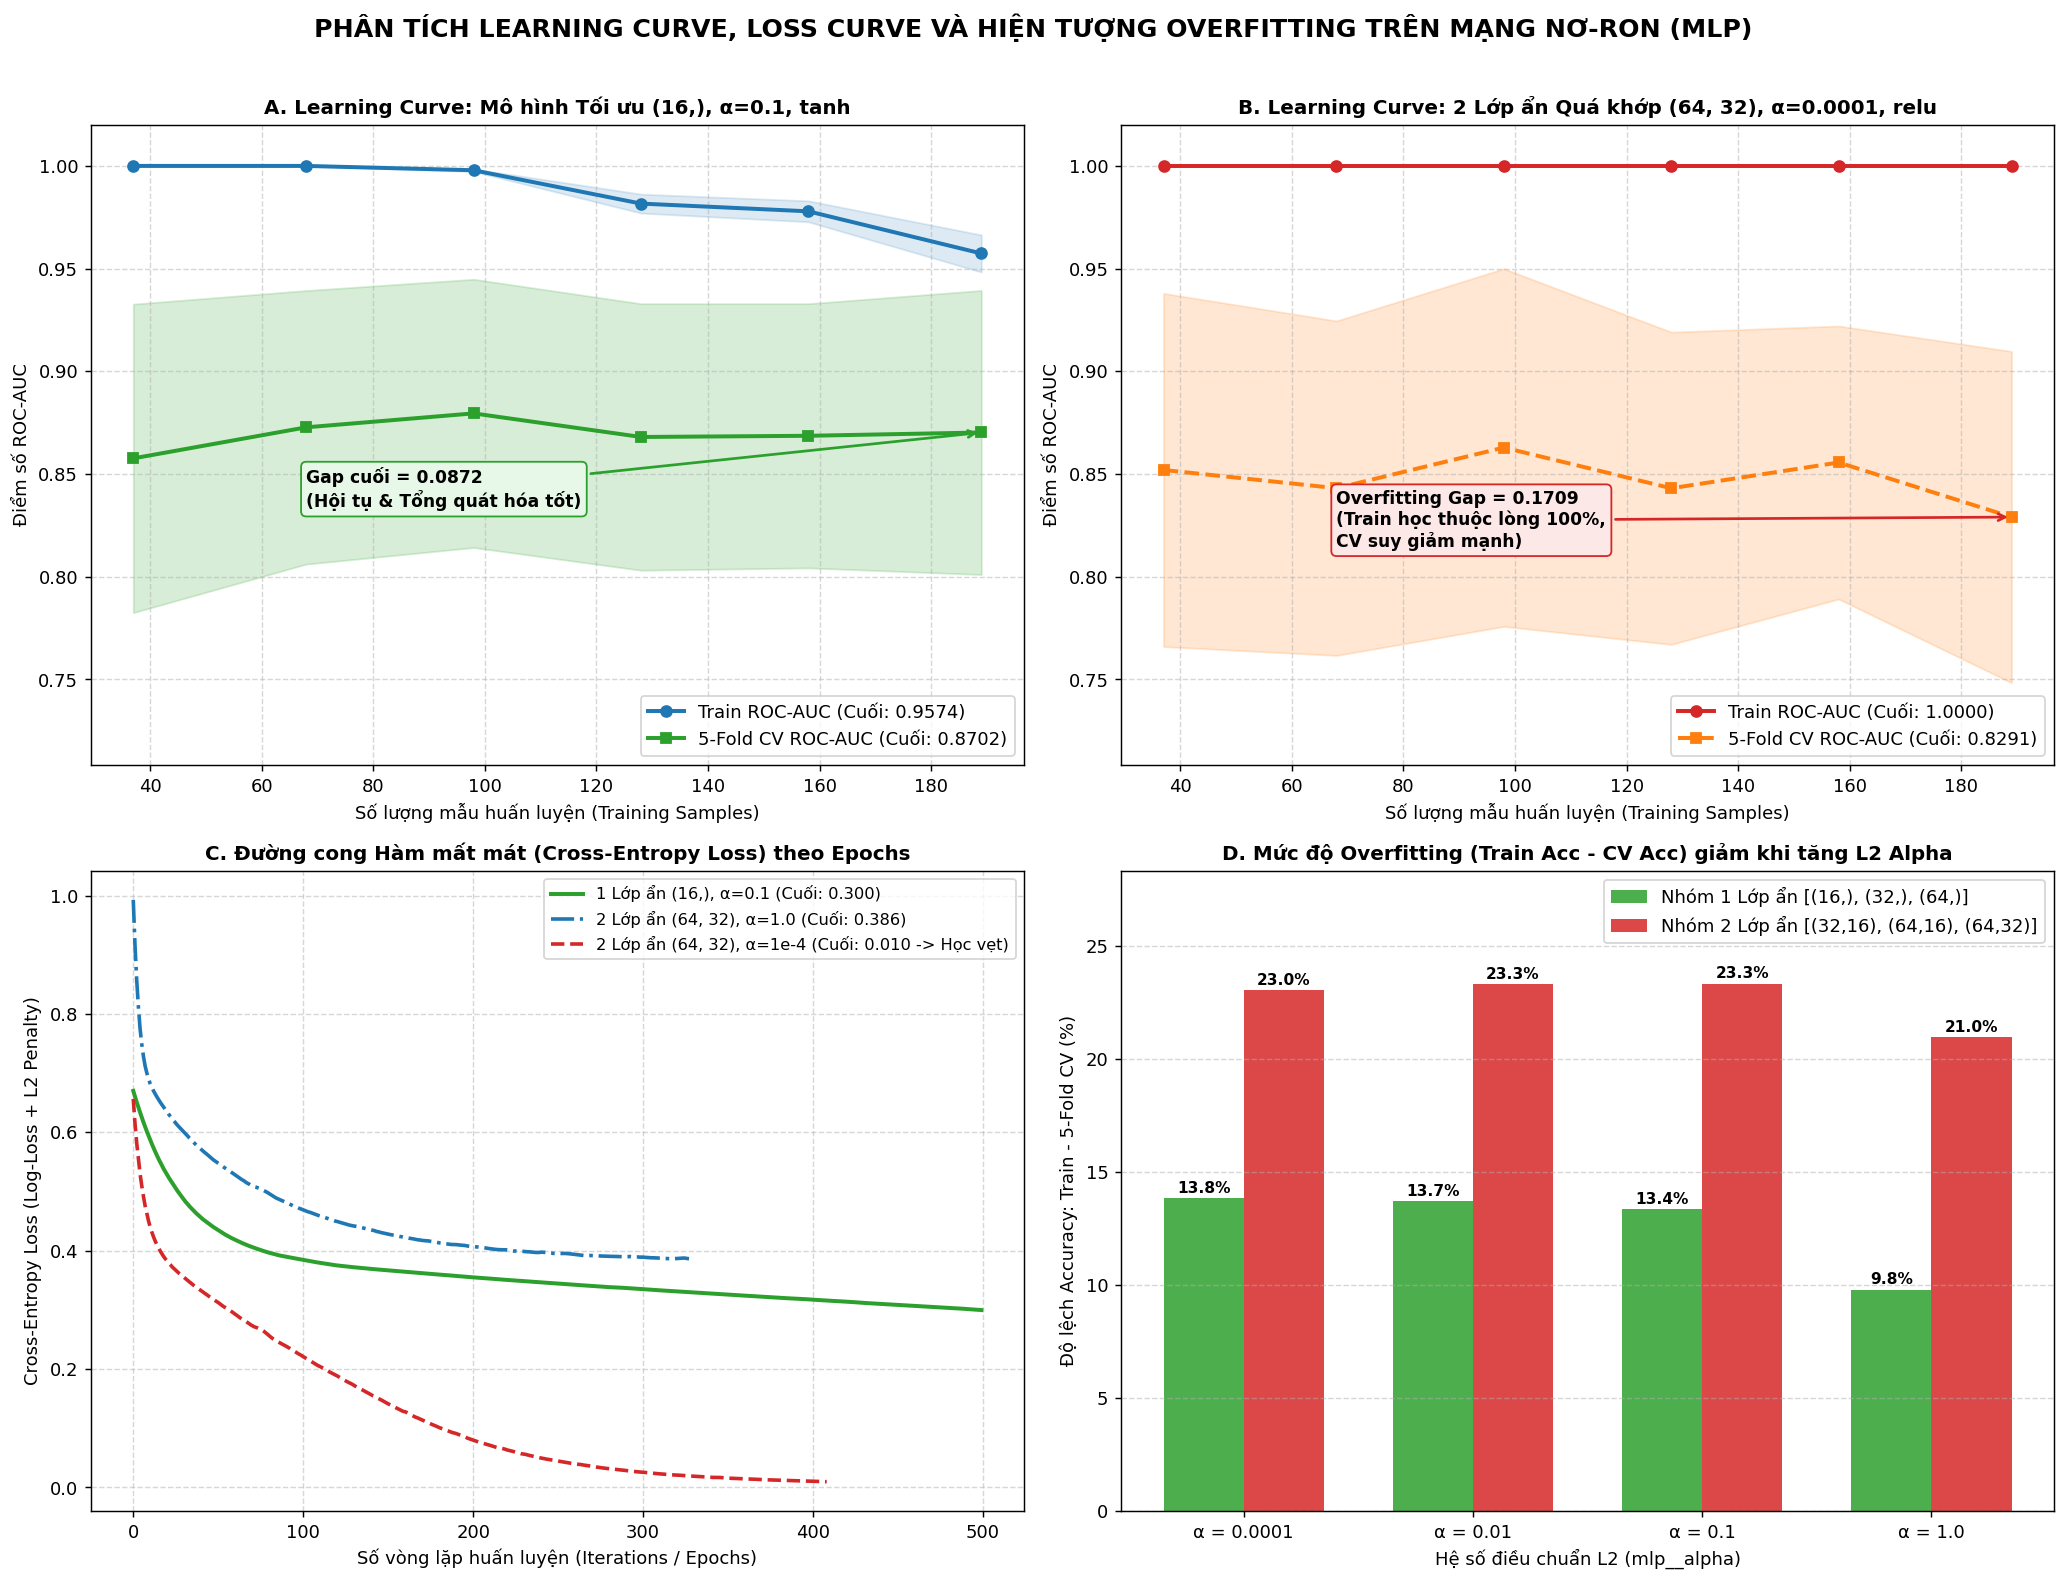

In [7]:
# ==============================================================================
# BƯỚC 5: TRỰC QUAN HÓA LEARNING CURVE, LOSS CURVE & PHÂN TÍCH OVERFITTING (DYNAMIC)
# ==============================================================================
plt.rcParams['font.size'] = 10
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=130)

# Tự động trích xuất tham số mô hình tối ưu nhất từ GridSearchCV
best_arch = grid_search.best_params_['mlp__hidden_layer_sizes']
best_alpha = grid_search.best_params_['mlp__alpha']
best_act = grid_search.best_params_['mlp__activation']

# Cấu hình 2 lớp ẩn đối chứng (Overfitting nặng nhất ở alpha nhỏ)
overfit_arch = (64, 32)
overfit_alpha = 0.0001
overfit_act = 'relu'

# Khởi tạo Pipeline động theo kết quả thực tế
pipe_best_1l = create_mlp_pipeline(X_train_raw, hidden_layer_sizes=best_arch, alpha=best_alpha, activation=best_act)
pipe_overfit_2l = create_mlp_pipeline(X_train_raw, hidden_layer_sizes=overfit_arch, alpha=overfit_alpha, activation=overfit_act)
pipe_reg_2l = create_mlp_pipeline(X_train_raw, hidden_layer_sizes=overfit_arch, alpha=1.0, activation='tanh')

train_sizes_frac = np.linspace(0.2, 1.0, 6)

# Tính Learning Curve cho mô hình tối ưu
ts_1l, tr_scores_1l, val_scores_1l = learning_curve(
    pipe_best_1l, X_train_raw, y_train, train_sizes=train_sizes_frac, cv=cv, scoring='roc_auc', n_jobs=-1
)
# Tính Learning Curve cho mô hình 2 lớp ẩn quá khớp
ts_2l, tr_scores_2l, val_scores_2l = learning_curve(
    pipe_overfit_2l, X_train_raw, y_train, train_sizes=train_sizes_frac, cv=cv, scoring='roc_auc', n_jobs=-1
)

tr_mean_1l, tr_std_1l = np.mean(tr_scores_1l, axis=1), np.std(tr_scores_1l, axis=1)
val_mean_1l, val_std_1l = np.mean(val_scores_1l, axis=1), np.std(val_scores_1l, axis=1)

tr_mean_2l, tr_std_2l = np.mean(tr_scores_2l, axis=1), np.std(tr_scores_2l, axis=1)
val_mean_2l, val_std_2l = np.mean(val_scores_2l, axis=1), np.std(val_scores_2l, axis=1)

# Tự động tính giới hạn trục Y để không bị cắt mất đường biểu đồ
y_min_lc = max(0.55, min(np.min(val_mean_1l - val_std_1l), np.min(val_mean_2l - val_std_2l)) - 0.04)

# --- HÌNH A: LEARNING CURVE MÔ HÌNH TỐI ƯU ---
ax = axes[0, 0]
ax.plot(ts_1l, tr_mean_1l, 'o-', color='#1f77b4', lw=2.2, label=f'Train ROC-AUC (Cuối: {tr_mean_1l[-1]:.4f})')
ax.fill_between(ts_1l, tr_mean_1l - tr_std_1l, np.minimum(1.01, tr_mean_1l + tr_std_1l), alpha=0.15, color='#1f77b4')
ax.plot(ts_1l, val_mean_1l, 's-', color='#2ca02c', lw=2.2, label=f'5-Fold CV ROC-AUC (Cuối: {val_mean_1l[-1]:.4f})')
ax.fill_between(ts_1l, val_mean_1l - val_std_1l, val_mean_1l + val_std_1l, alpha=0.18, color='#2ca02c')

gap_1l_end = tr_mean_1l[-1] - val_mean_1l[-1]
mid_y_1l = (tr_mean_1l[-1] + val_mean_1l[-1]) / 2
ax.annotate(
    f'Gap cuối = {gap_1l_end:.4f}\n(Hội tụ & Tổng quát hóa tốt)',
    xy=(ts_1l[-1], val_mean_1l[-1]),
    xytext=(ts_1l[1], max(y_min_lc + 0.03, mid_y_1l - 0.08)),
    arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=1.5),
    fontsize=9.5, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#e8f8e8', edgecolor='#2ca02c')
)
ax.set_title(f'A. Learning Curve: Mô hình Tối ưu {best_arch}, α={best_alpha}, {best_act}', fontweight='bold', fontsize=11)
ax.set_xlabel('Số lượng mẫu huấn luyện (Training Samples)')
ax.set_ylabel('Điểm số ROC-AUC')
ax.set_ylim(y_min_lc, 1.02)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

# --- HÌNH B: LEARNING CURVE MÔ HÌNH 2 LỚP ẨN OVERFITTING ---
ax = axes[0, 1]
ax.plot(ts_2l, tr_mean_2l, 'o-', color='#d62728', lw=2.2, label=f'Train ROC-AUC (Cuối: {tr_mean_2l[-1]:.4f})')
ax.fill_between(ts_2l, tr_mean_2l - tr_std_2l, np.minimum(1.01, tr_mean_2l + tr_std_2l), alpha=0.15, color='#d62728')
ax.plot(ts_2l, val_mean_2l, 's--', color='#ff7f0e', lw=2.2, label=f'5-Fold CV ROC-AUC (Cuối: {val_mean_2l[-1]:.4f})')
ax.fill_between(ts_2l, val_mean_2l - val_std_2l, val_mean_2l + val_std_2l, alpha=0.18, color='#ff7f0e')

gap_2l_end = tr_mean_2l[-1] - val_mean_2l[-1]
mid_y_2l = (tr_mean_2l[-1] + val_mean_2l[-1]) / 2
ax.annotate(
    f'Overfitting Gap = {gap_2l_end:.4f}\n(Train học thuộc lòng 100%,\nCV suy giảm mạnh)',
    xy=(ts_2l[-1], val_mean_2l[-1]),
    xytext=(ts_2l[1], max(y_min_lc + 0.03, mid_y_2l - 0.10)),
    arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
    fontsize=9.5, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#fde8e8', edgecolor='#d62728')
)
ax.set_title(f'B. Learning Curve: 2 Lớp ẩn Quá khớp {overfit_arch}, α={overfit_alpha}, {overfit_act}', fontweight='bold', fontsize=11)
ax.set_xlabel('Số lượng mẫu huấn luyện (Training Samples)')
ax.set_ylabel('Điểm số ROC-AUC')
ax.set_ylim(y_min_lc, 1.02)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

# --- HÌNH C: LOSS CURVE THEO EPOCHS ---
ax = axes[1, 0]
pipe_best_1l.fit(X_train_raw, y_train)
pipe_overfit_2l.fit(X_train_raw, y_train)
pipe_reg_2l.fit(X_train_raw, y_train)

loss_best_1l = pipe_best_1l.named_steps['mlp'].loss_curve_
loss_overfit_2l = pipe_overfit_2l.named_steps['mlp'].loss_curve_
loss_reg_2l = pipe_reg_2l.named_steps['mlp'].loss_curve_

ax.plot(loss_best_1l, color='#2ca02c', lw=2.2, label=f'1 Lớp ẩn {best_arch}, α={best_alpha} (Cuối: {loss_best_1l[-1]:.3f})')
ax.plot(loss_reg_2l, color='#1f77b4', lw=2.0, linestyle='-.', label=f'2 Lớp ẩn (64, 32), α=1.0 (Cuối: {loss_reg_2l[-1]:.3f})')
ax.plot(loss_overfit_2l, color='#d62728', lw=2.0, linestyle='--', label=f'2 Lớp ẩn (64, 32), α=1e-4 (Cuối: {loss_overfit_2l[-1]:.3f} -> Học vẹt)')

ax.set_title('C. Đường cong Hàm mất mát (Cross-Entropy Loss) theo Epochs', fontweight='bold', fontsize=11)
ax.set_xlabel('Số vòng lặp huấn luyện (Iterations / Epochs)')
ax.set_ylabel('Cross-Entropy Loss (Log-Loss + L2 Penalty)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', fontsize=9)

# --- HÌNH D: ĐỘ CHÊNH LỆCH OVERFITTING (TRAIN ACC - CV ACC) THEO ALPHA ---
ax = axes[1, 1]
gap_pivot = cv_df.groupby(['param_mlp__alpha', 'num_layers'])['gap_acc'].mean().unstack()
x_pos = np.arange(len(gap_pivot.index))
width = 0.35

rects1 = ax.bar(x_pos - width/2, gap_pivot['1 Lớp ẩn (1-Layer)'] * 100, width, label='Nhóm 1 Lớp ẩn [(16,), (32,), (64,)]', color='#2ca02c', alpha=0.85)
rects2 = ax.bar(x_pos + width/2, gap_pivot['2 Lớp ẩn (2-Layers)'] * 100, width, label='Nhóm 2 Lớp ẩn [(32,16), (64,16), (64,32)]', color='#d62728', alpha=0.85)

ax.set_title('D. Mức độ Overfitting (Train Acc - CV Acc) giảm khi tăng L2 Alpha', fontweight='bold', fontsize=11)
ax.set_xticks(x_pos)
ax.set_xticklabels([f'α = {a}' for a in gap_pivot.index])
ax.set_xlabel('Hệ số điều chuẩn L2 (mlp__alpha)')
ax.set_ylabel('Độ lệch Accuracy: Train - 5-Fold CV (%)')
max_bar_h = max(gap_pivot['1 Lớp ẩn (1-Layer)'].max(), gap_pivot['2 Lớp ẩn (2-Layers)'].max()) * 100
ax.set_ylim(0, max_bar_h + 5)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right')

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')

plt.suptitle('PHÂN TÍCH LEARNING CURVE, LOSS CURVE VÀ HIỆN TƯỢNG OVERFITTING TRÊN MẠNG NƠ-RON (MLP)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('MLP_Learning_Curve_Overfitting.png', bbox_inches='tight')
plt.show()

BÁO CÁO KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (N_test = 60 MẪU):
Mô hình tối ưu từ CV: hidden_layer_sizes=(16,), alpha=0.1, activation='tanh'
  - Test Accuracy  : 0.8167 (81.67%)  | [Đối chiếu 5-Fold CV: 0.8015 +/- 0.0655]
  - Test Precision : 0.8148 (81.48%)  | [Đối chiếu 5-Fold CV: 0.7939]
  - Test Recall    : 0.7857 (78.57%)  | [Đối chiếu 5-Fold CV: 0.7784]
  - Test F1-score  : 0.8000 (80.00%)  | [Đối chiếu 5-Fold CV: 0.7813]
  - Test ROC-AUC   : 0.9487 (94.87%)  | [Đối chiếu 5-Fold CV: 0.8728 +/- 0.0630]
----------------------------------------------------------------------------------
Chi tiết Classification Report trên tập Test:
                precision    recall  f1-score   support

Không bệnh (0)     0.8182    0.8438    0.8308        32
  Bệnh tim (1)     0.8148    0.7857    0.8000        28

      accuracy                         0.8167        60
     macro avg     0.8165    0.8147    0.8154        60
  weighted avg     0.8166    0.8167    0.8164        60



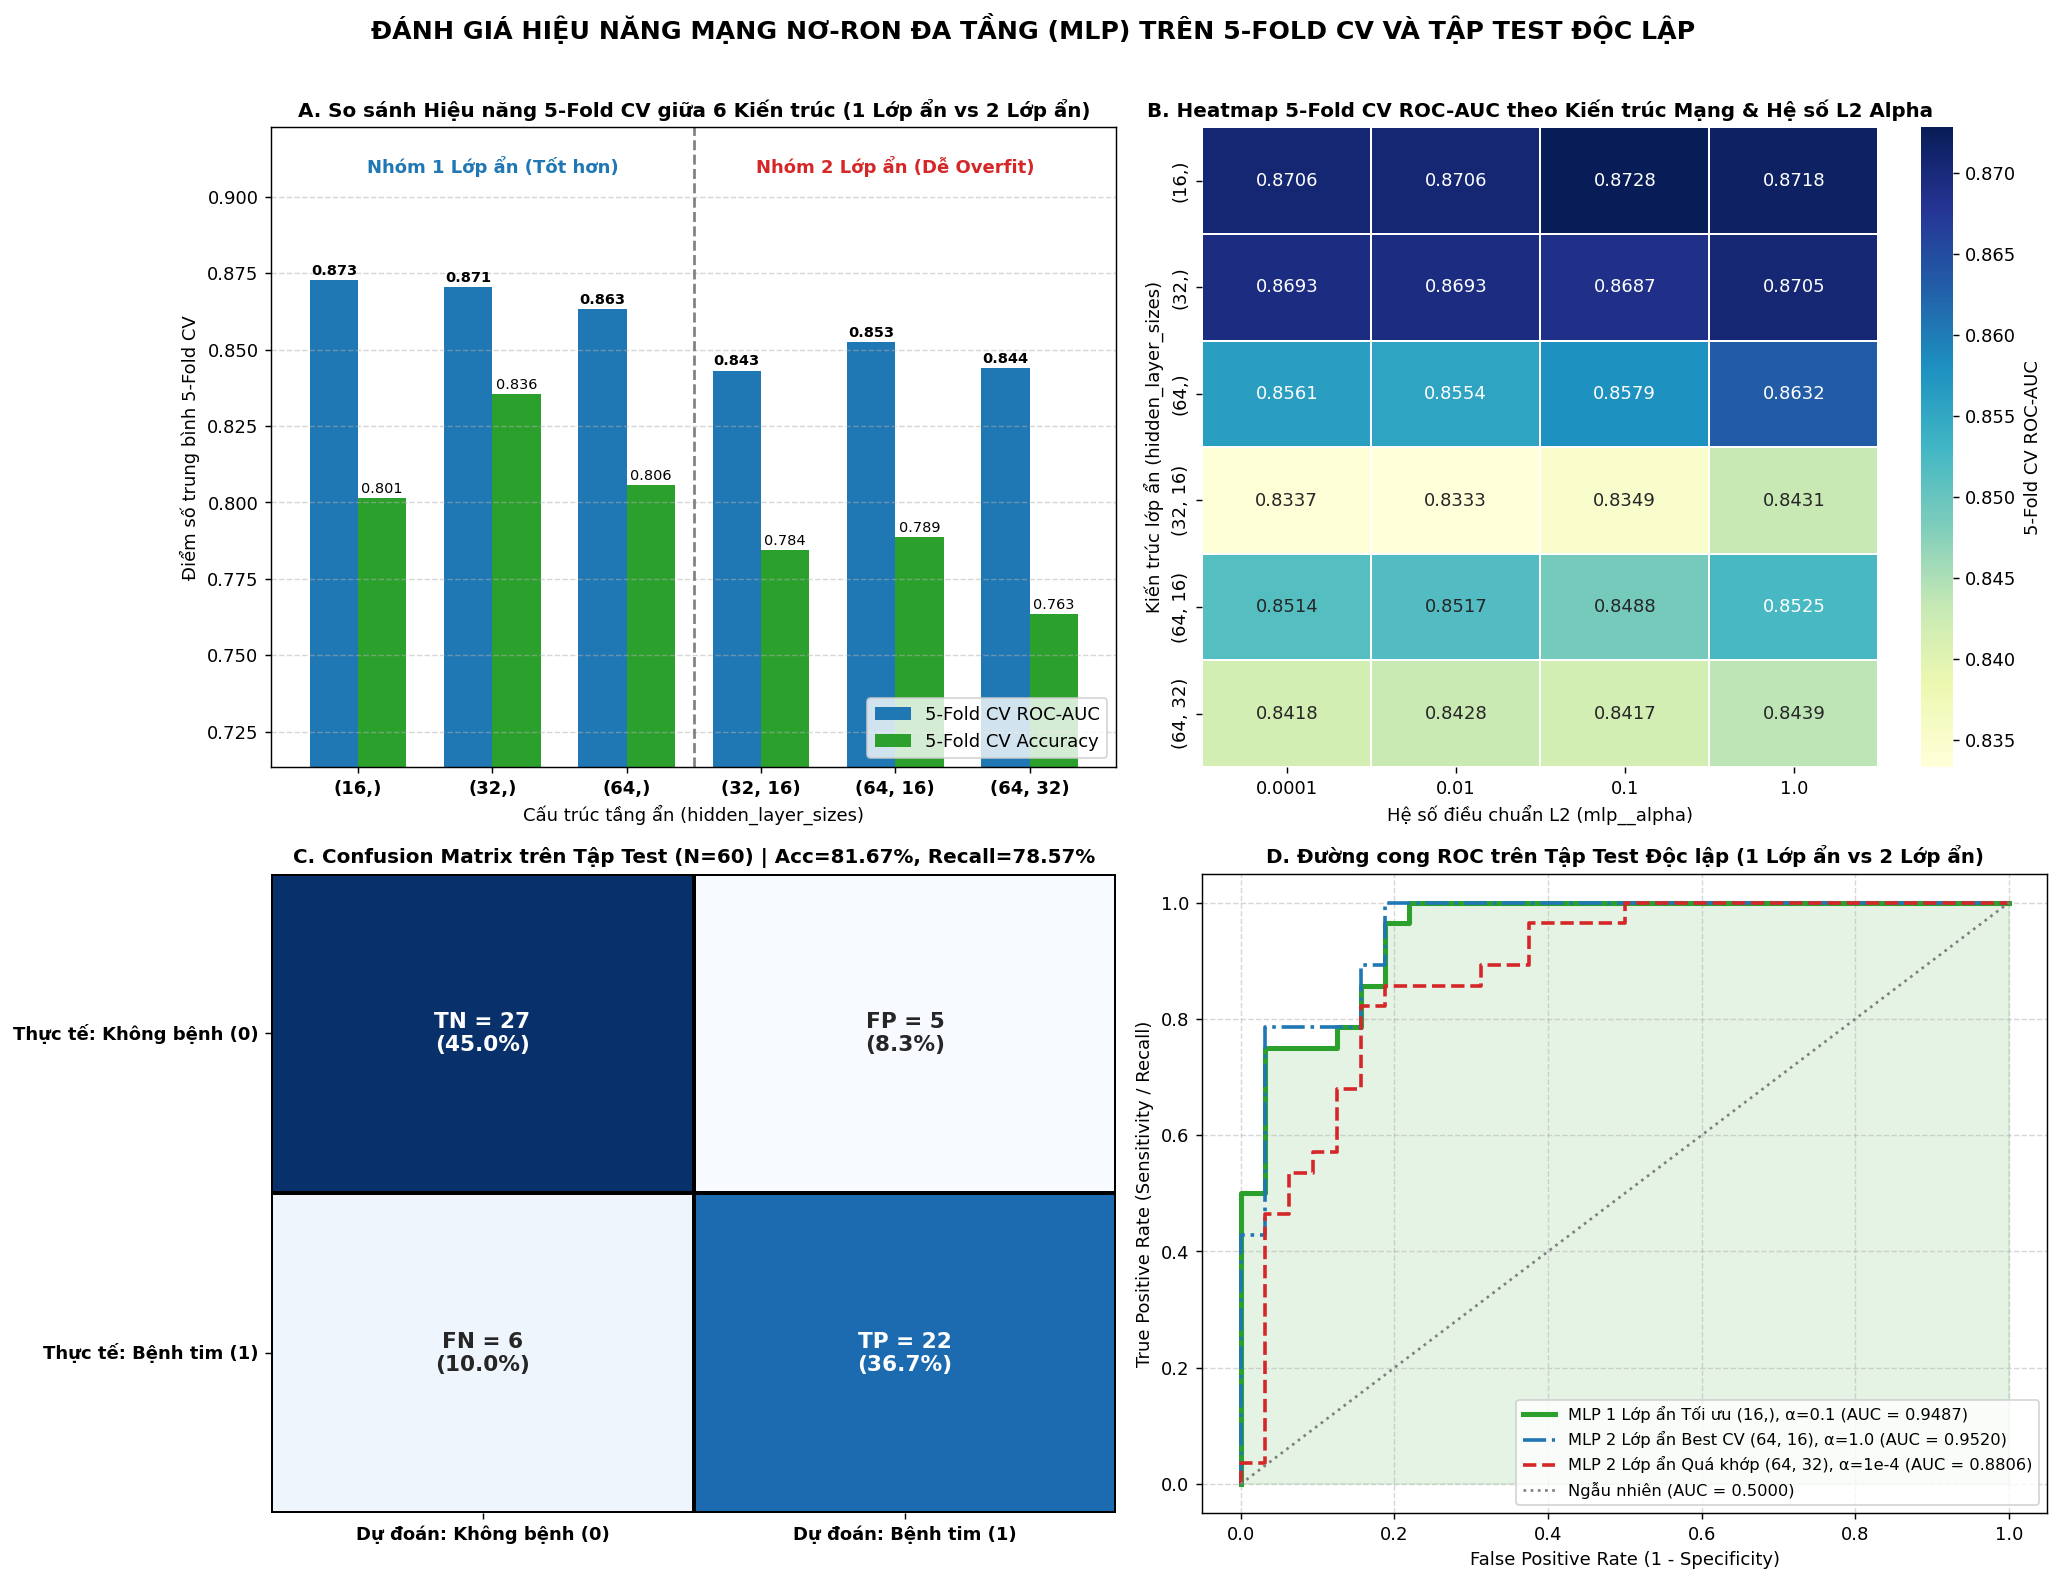

In [8]:
# ==============================================================================
# BƯỚC 6: ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST & VẼ CONFUSION MATRIX, ROC CURVE, HEATMAP
# ==============================================================================
best_model = grid_search.best_estimator_

# Dự đoán trên tập Test độc lập (60 mẫu)
y_pred = best_model.predict(X_test_raw)
y_score = best_model.predict_proba(X_test_raw)[:, 1]

test_acc  = accuracy_score(y_test, y_pred)
test_prec = precision_score(y_test, y_pred)
test_rec  = recall_score(y_test, y_pred)
test_f1   = f1_score(y_test, y_pred)
test_auc  = roc_auc_score(y_test, y_score)

# Tự động tìm cấu hình 2 lớp ẩn tốt nhất từ bảng CV để so sánh công bằng với 1 lớp ẩn
best_2l_row = cv_df[cv_df['num_layers'] == '2 Lớp ẩn (2-Layers)'].sort_values(by='mean_test_roc_auc', ascending=False).iloc[0]
best_2l_arch = best_2l_row['param_mlp__hidden_layer_sizes']
best_2l_alpha = best_2l_row['param_mlp__alpha']
best_2l_act = best_2l_row['param_mlp__activation']

pipe_best_2l = create_mlp_pipeline(X_train_raw, hidden_layer_sizes=best_2l_arch, alpha=best_2l_alpha, activation=best_2l_act)
pipe_best_2l.fit(X_train_raw, y_train)
y_score_2l_reg = pipe_best_2l.predict_proba(X_test_raw)[:, 1]
y_score_2l_overfit = pipe_overfit_2l.predict_proba(X_test_raw)[:, 1]

print("=" * 82)
print(f"BÁO CÁO KẾT QUẢ ĐÁNH GIÁ ĐỘC LẬP TRÊN TẬP TEST (N_test = {len(y_test)} MẪU):")
print(f"Mô hình tối ưu từ CV: hidden_layer_sizes={best_arch}, alpha={best_alpha}, activation='{best_act}'")
print("=" * 82)
print(f"  - Test Accuracy  : {test_acc:.4f} ({test_acc*100:.2f}%)  | [Đối chiếu 5-Fold CV: {best_row['mean_test_accuracy']:.4f} +/- {best_row['std_test_accuracy']:.4f}]")
print(f"  - Test Precision : {test_prec:.4f} ({test_prec*100:.2f}%)  | [Đối chiếu 5-Fold CV: {best_row['mean_test_precision']:.4f}]")
print(f"  - Test Recall    : {test_rec:.4f} ({test_rec*100:.2f}%)  | [Đối chiếu 5-Fold CV: {best_row['mean_test_recall']:.4f}]")
print(f"  - Test F1-score  : {test_f1:.4f} ({test_f1*100:.2f}%)  | [Đối chiếu 5-Fold CV: {best_row['mean_test_f1']:.4f}]")
print(f"  - Test ROC-AUC   : {test_auc:.4f} ({test_auc*100:.2f}%)  | [Đối chiếu 5-Fold CV: {best_row['mean_test_roc_auc']:.4f} +/- {best_row['std_test_roc_auc']:.4f}]")
print("-" * 82)
print("Chi tiết Classification Report trên tập Test:")
print(classification_report(y_test, y_pred, target_names=['Không bệnh (0)', 'Bệnh tim (1)'], digits=4))

# --- VẼ BỘ 4 BIỂU ĐỒ TỔNG HỢP KIẾN TRÚC & ĐÁNH GIÁ TẬP TEST ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=130)

# 1. Biểu đồ cột so sánh 6 kiến trúc (1 lớp ẩn vs 2 lớp ẩn)
ax = axes[0, 0]
x_arch = np.arange(len(summary_arch_df))
w = 0.36
b1 = ax.bar(x_arch - w/2, summary_arch_df['CV ROC-AUC (Best α)'], w, label='5-Fold CV ROC-AUC', color='#1f77b4')
b2 = ax.bar(x_arch + w/2, summary_arch_df['CV Acc (Best α)'], w, label='5-Fold CV Accuracy', color='#2ca02c')
ax.axvline(2.5, color='gray', linestyle='--', lw=1.5)

min_bar_val = min(summary_arch_df['CV ROC-AUC (Best α)'].min(), summary_arch_df['CV Acc (Best α)'].min())
max_bar_val = max(summary_arch_df['CV ROC-AUC (Best α)'].max(), summary_arch_df['CV Acc (Best α)'].max())
y_low_bar = max(0.65, min_bar_val - 0.05)
y_high_bar = min(1.0, max_bar_val + 0.05)

ax.text(1.0, y_high_bar - 0.015, 'Nhóm 1 Lớp ẩn (Tốt hơn)', ha='center', fontweight='bold', color='#1f77b4', fontsize=10)
ax.text(4.0, y_high_bar - 0.015, 'Nhóm 2 Lớp ẩn (Dễ Overfit)', ha='center', fontweight='bold', color='#d62728', fontsize=10)
ax.set_xticks(x_arch)
ax.set_xticklabels(summary_arch_df['Kiến trúc'], fontweight='bold')
ax.set_ylim(y_low_bar, y_high_bar)
ax.set_title('A. So sánh Hiệu năng 5-Fold CV giữa 6 Kiến trúc (1 Lớp ẩn vs 2 Lớp ẩn)', fontweight='bold', fontsize=11)
ax.set_xlabel('Cấu trúc tầng ẩn (hidden_layer_sizes)')
ax.set_ylabel('Điểm số trung bình 5-Fold CV')
ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='lower right')

for bar in b1:
    ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width()/2, bar.get_height()), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8, fontweight='bold')
for bar in b2:
    ax.annotate(f"{bar.get_height():.3f}", (bar.get_x() + bar.get_width()/2, bar.get_height()), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8)

# 2. Heatmap tương tác giữa Kiến trúc và Alpha đối với CV ROC-AUC
ax = axes[0, 1]
hm_data = cv_df.groupby(['arch_str', 'param_mlp__alpha'])['mean_test_roc_auc'].max().unstack()
hm_data = hm_data.loc[arch_list]
sns.heatmap(hm_data, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': '5-Fold CV ROC-AUC'}, ax=ax, linewidths=1)
ax.set_title('B. Heatmap 5-Fold CV ROC-AUC theo Kiến trúc Mạng & Hệ số L2 Alpha', fontweight='bold', fontsize=11)
ax.set_xlabel('Hệ số điều chuẩn L2 (mlp__alpha)')
ax.set_ylabel('Kiến trúc lớp ẩn (hidden_layer_sizes)')

# 3. Confusion Matrix trên tập Test
ax = axes[1, 0]
cm = confusion_matrix(y_test, y_pred)
cm_labels = [
    [f"TN = {cm[0,0]}\n({cm[0,0]/len(y_test)*100:.1f}%)", f"FP = {cm[0,1]}\n({cm[0,1]/len(y_test)*100:.1f}%)"],
    [f"FN = {cm[1,0]}\n({cm[1,0]/len(y_test)*100:.1f}%)", f"TP = {cm[1,1]}\n({cm[1,1]/len(y_test)*100:.1f}%)"]
]
sns.heatmap(cm, annot=cm_labels, fmt="", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 12, "weight": "bold"}, linewidths=2, linecolor='black')
ax.set_xticklabels(['Dự đoán: Không bệnh (0)', 'Dự đoán: Bệnh tim (1)'], fontweight='bold')
ax.set_yticklabels(['Thực tế: Không bệnh (0)', 'Thực tế: Bệnh tim (1)'], fontweight='bold', rotation=0)
ax.set_title(f'C. Confusion Matrix trên Tập Test (N={len(y_test)}) | Acc={test_acc*100:.2f}%, Recall={test_rec*100:.2f}%', fontweight='bold', fontsize=11)

# 4. Đường cong ROC trên tập Test (So sánh 1 lớp ẩn vs 2 lớp ẩn)
ax = axes[1, 1]
fpr_1l, tpr_1l, _ = roc_curve(y_test, y_score)
fpr_2l_reg, tpr_2l_reg, _ = roc_curve(y_test, y_score_2l_reg)
fpr_2l_ovf, tpr_2l_ovf, _ = roc_curve(y_test, y_score_2l_overfit)

auc_2l_reg = roc_auc_score(y_test, y_score_2l_reg)
auc_2l_ovf = roc_auc_score(y_test, y_score_2l_overfit)

ax.plot(fpr_1l, tpr_1l, color='#2ca02c', lw=2.8, label=f'MLP 1 Lớp ẩn Tối ưu {best_arch}, α={best_alpha} (AUC = {test_auc:.4f})')
ax.plot(fpr_2l_reg, tpr_2l_reg, color='#1f77b4', lw=2.0, linestyle='-.', label=f'MLP 2 Lớp ẩn Best CV {best_2l_arch}, α={best_2l_alpha} (AUC = {auc_2l_reg:.4f})')
ax.plot(fpr_2l_ovf, tpr_2l_ovf, color='#d62728', lw=2.0, linestyle='--', label=f'MLP 2 Lớp ẩn Quá khớp {overfit_arch}, α=1e-4 (AUC = {auc_2l_ovf:.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.5, label='Ngẫu nhiên (AUC = 0.5000)')
ax.fill_between(fpr_1l, tpr_1l, alpha=0.12, color='#2ca02c')
ax.set_title('D. Đường cong ROC trên Tập Test Độc lập (1 Lớp ẩn vs 2 Lớp ẩn)', fontweight='bold', fontsize=11)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower right', fontsize=9)

plt.suptitle('ĐÁNH GIÁ HIỆU NĂNG MẠNG NƠ-RON ĐA TẦNG (MLP) TRÊN 5-FOLD CV VÀ TẬP TEST ĐỘC LẬP', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('MLP_Architecture_Test_Evaluation.png', bbox_inches='tight')
plt.show()

In [9]:
# ==============================================================================
# BƯỚC 7: XUẤT DICTIONARY KẾT QUẢ CHUẨN CONTRACT & LƯU FILE
# ==============================================================================
OUTPUT_DIR = "./04_MLP_Outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Tạo chuỗi Note động dựa trên đúng kết quả thực nghiệm vừa chạy
note_str = (
    f"1 lớp ẩn {best_arch} với L2 alpha={best_alpha} ({best_act}) đạt CV ROC-AUC cao nhất ({best_row['mean_test_roc_auc']:.4f}), "
    f"kiểm soát overfitting tốt hơn 2 lớp ẩn {best_2l_arch} (CV ROC-AUC={best_2l_row['mean_test_roc_auc']:.4f}); "
    f"Test độc lập (N={len(y_test)}): Acc={test_acc:.4f}, Precision={test_prec:.4f}, Recall={test_rec:.4f}, F1={test_f1:.4f}, ROC-AUC={test_auc:.4f}."
)

# Dictionary chuẩn tuyệt đối theo Mục 3 & Mục 6 của Contract (Chỉ số _mean, _std tính từ 5-Fold CV trên tập Train)
mlp_result_dict = {
    "Model": "MLP (Neural Network)",
    "Accuracy_mean": round(float(best_row['mean_test_accuracy']), 4),
    "Accuracy_std": round(float(best_row['std_test_accuracy']), 4),
    "Precision_mean": round(float(best_row['mean_test_precision']), 4),
    "Recall_mean": round(float(best_row['mean_test_recall']), 4),
    "F1_mean": round(float(best_row['mean_test_f1']), 4),
    "ROC_AUC_mean": round(float(best_row['mean_test_roc_auc']), 4),
    "Best_params": {
        "hidden_layer_sizes": best_arch,
        "alpha": float(best_alpha),
        "activation": str(best_act)
    },
    "Note": note_str
}

# Lưu y_pred, y_score trên tập Test và Dictionary để  tổng hợp
np.save(os.path.join(OUTPUT_DIR, "y_pred_MLP.npy"), y_pred)
np.save(os.path.join(OUTPUT_DIR, "y_score_MLP.npy"), y_score)
joblib.dump(best_model, os.path.join(OUTPUT_DIR, "best_mlp_pipeline.joblib"))

with open(os.path.join(OUTPUT_DIR, "MLP_result_dict.json"), "w", encoding="utf-8") as f:
    json.dump(mlp_result_dict, f, ensure_ascii=False, indent=4)

print("1. DICTIONARY KẾT QUẢ CHUẨN CONTRACT :")
print(json.dumps(mlp_result_dict, ensure_ascii=False, indent=4))
print("\n2. KIỂM TRA MẢNG DỰ ĐOÁN TẬP TEST :")
print(f"   - y_pred_MLP.npy  : shape = {y_pred.shape}, dtype = {y_pred.dtype}, mẫu đầu = {y_pred[:10]}")
print(f"   - y_score_MLP.npy : shape = {y_score.shape}, dtype = {y_score.dtype}, mẫu đầu = {np.round(y_score[:5], 4)}")
print(f"   - Thư mục lưu trữ : {os.path.abspath(OUTPUT_DIR)}")

1. DICTIONARY KẾT QUẢ CHUẨN CONTRACT :
{
    "Model": "MLP (Neural Network)",
    "Accuracy_mean": 0.8015,
    "Accuracy_std": 0.0655,
    "Precision_mean": 0.7939,
    "Recall_mean": 0.7784,
    "F1_mean": 0.7813,
    "ROC_AUC_mean": 0.8728,
    "Best_params": {
        "hidden_layer_sizes": [
            16
        ],
        "alpha": 0.1,
        "activation": "tanh"
    },
    "Note": "1 lớp ẩn (16,) với L2 alpha=0.1 (tanh) đạt CV ROC-AUC cao nhất (0.8728), kiểm soát overfitting tốt hơn 2 lớp ẩn (64, 16) (CV ROC-AUC=0.8525); Test độc lập (N=60): Acc=0.8167, Precision=0.8148, Recall=0.7857, F1=0.8000, ROC-AUC=0.9487."
}

2. KIỂM TRA MẢNG DỰ ĐOÁN TẬP TEST :
   - y_pred_MLP.npy  : shape = (60,), dtype = int64, mẫu đầu = [0 0 0 0 1 0 1 0 0 0]
   - y_score_MLP.npy : shape = (60,), dtype = float64, mẫu đầu = [0.0198 0.0299 0.3618 0.1626 0.666 ]
   - Thư mục lưu trữ : /content/04_MLP_Outputs
